# Figure S7 — cross-assay ON-ensemble membership

This plot-only notebook renders Figure S7 from two compact source files. It does not reopen raw recordings or redefine preprocessing functions.

**S7A encoding is categorical, not continuous:** `1` (magenta) means ON-ensemble member; `0` (cyan) means a valid classification that is not an ON-ensemble membership; missing/`NaN` (white) means that classification was unavailable. White must never be converted to zero.

The compact heatmap table preserves the accepted-panel serialization: the first 187 rows are WT neurons and the following 100 rows are RTT neurons. Assertions below verify those blocks against every published S7B numerator and denominator.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    'font.size': 9,
    'figure.dpi': 120,
})

ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'pyproject.toml').is_file()
)
SOURCE = ROOT / 'data' / 'source_data' / 'figure_s07'
FIGURES = ROOT / 'results' / 'figures'
TABLES = ROOT / 'results' / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print('Repository root located from pyproject.toml.')

Repository root located from pyproject.toml.


## S7A — availability-aware membership heatmaps

Rows are sorted by center-ON and then corner-ON membership within genotype. Missing classifications remain masked and white.

In [2]:
s7a = pd.read_csv(
    SOURCE / 's7a_all_oft_on.csv',
    keep_default_na=False,
    na_values=[''],
)
s7a = s7a.loc[:, ~s7a.columns.astype(str).str.startswith('Unnamed:')]

heatmap_columns = [
    'CenterON', 'CornerON',
    'OpenON', 'CloseON', 'openPreferedON', 'openNonPreferedON',
    'closePreferedON', 'closeNonPreferedON',
    'S1_SocialON', 'S1_ObjectON', 'S2_SocialON', 'S2_ObjectON',
    'S3_SocialON', 'S3_ObjectON',
]
heatmap_labels = [
    'Center-ON', 'Corner-ON',
    'Opened-ON', 'Closed-ON', 'Opened-P-ON', 'Opened-NP-ON',
    'Closed-P-ON', 'Closed-NP-ON',
    'S1_Social-ON', 'S1_Object-ON', 'S2_Social-ON', 'S2_Object-ON',
    'S3_Social-ON', 'S3_Object-ON',
]

assert len(s7a) == 287, f'Expected 287 heatmap rows, found {len(s7a)}.'
assert set(heatmap_columns).issubset(s7a.columns)
for column in heatmap_columns:
    s7a[column] = pd.to_numeric(s7a[column], errors='coerce')
    observed = set(s7a[column].dropna().unique())
    assert observed.issubset({0.0, 1.0}), f'{column} contains non-binary values: {observed}'

s7a.insert(0, 'cohort', np.where(np.arange(len(s7a)) < 187, 'WT', 'RTT'))
assert s7a['cohort'].value_counts().to_dict() == {'WT': 187, 'RTT': 100}

sorted_heatmaps = {}
availability_rows = []
for cohort in ['WT', 'RTT']:
    cohort_table = s7a.loc[s7a['cohort'].eq(cohort)].sort_values(
        ['CenterON', 'CornerON'], ascending=[False, False], kind='mergesort'
    ).reset_index(drop=True)
    sorted_heatmaps[cohort] = cohort_table
    for column, label in zip(heatmap_columns, heatmap_labels):
        availability_rows.append({
            'genotype': cohort,
            'classification': label,
            'total_heatmap_neurons': len(cohort_table),
            'on_members': int(cohort_table[column].eq(1).sum()),
            'valid_nonmembers': int(cohort_table[column].eq(0).sum()),
            'classification_unavailable': int(cohort_table[column].isna().sum()),
        })

availability = pd.DataFrame(availability_rows)
availability.to_csv(TABLES / 'fig_s7a_membership_availability.csv', index=False)


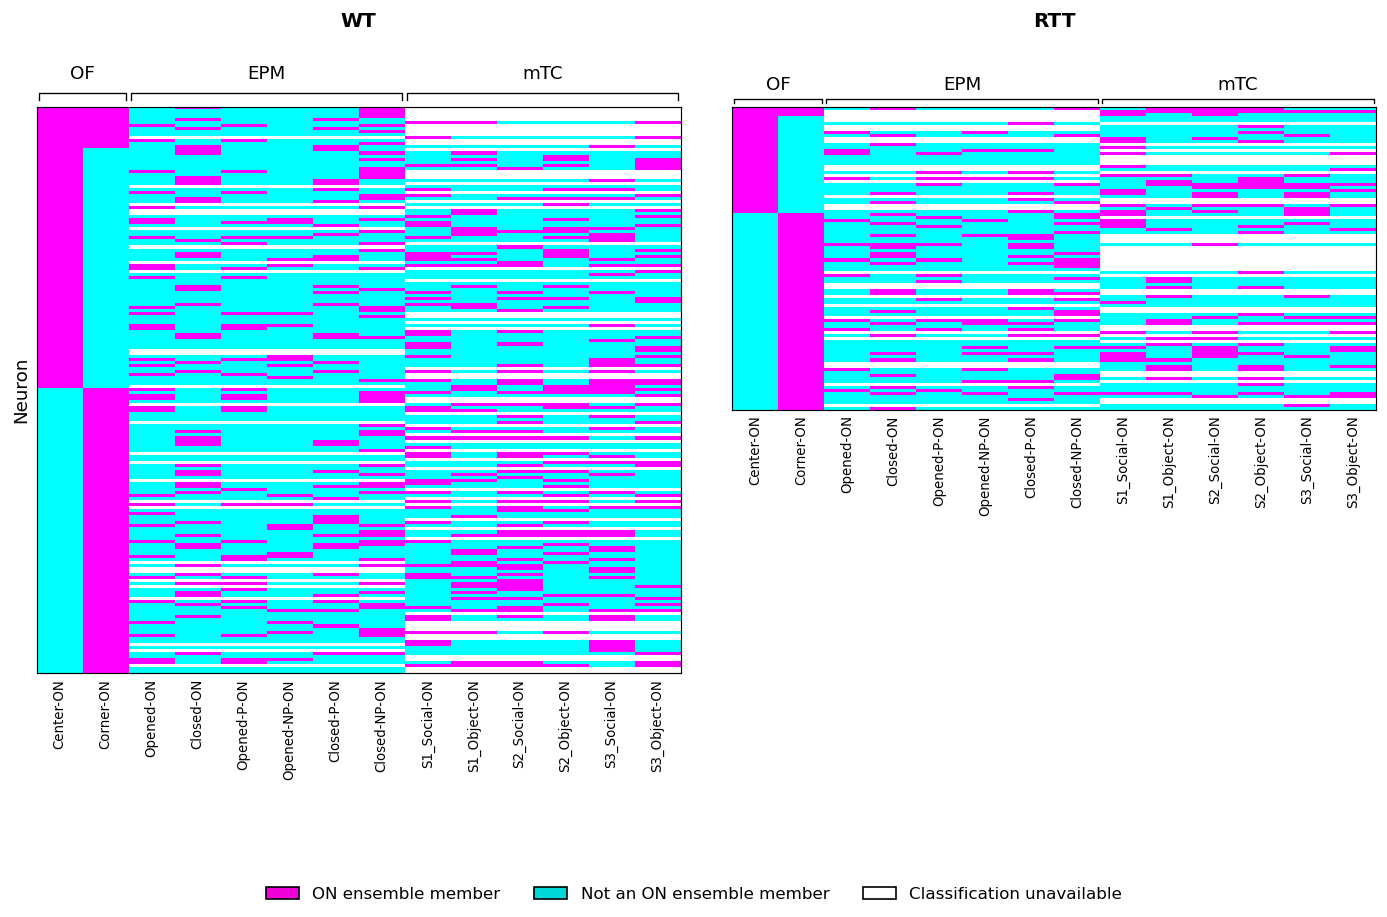

In [3]:
fig = plt.figure(figsize=(12, 8))
grid = fig.add_gridspec(187, 2, width_ratios=[1, 1], wspace=0.08)
axes = [fig.add_subplot(grid[:, 0]), fig.add_subplot(grid[:100, 1])]
for ax, cohort in zip(axes, ['WT', 'RTT']):
    matrix = sorted_heatmaps[cohort][heatmap_columns].to_numpy(dtype=float)
    ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap='cool', vmin=0, vmax=1, interpolation='nearest', aspect='auto',
    )
    ax.set_title(f'{cohort}', fontsize=12, weight='bold', pad=48)
    ax.set_xticks(np.arange(len(heatmap_labels)), heatmap_labels, rotation=90, fontsize=8)
    ax.set_yticks([])
    ax.tick_params(axis='x', length=0)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)
    for start, end, label in [(0, 1, 'OF'), (2, 7, 'EPM'), (8, 13, 'mTC')]:
        y = 1.025
        ax.plot(
            [start - 0.45, start - 0.45, end + 0.45, end + 0.45],
            [y - 0.012, y, y, y - 0.012],
            transform=ax.get_xaxis_transform(), color='black', linewidth=0.8, clip_on=False,
        )
        ax.text(
            (start + end) / 2, y + 0.018, label, transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', fontsize=11, clip_on=False,
        )
axes[0].set_ylabel('Neuron', fontsize=11)

legend_handles = [
    Patch(facecolor='#F000D8', edgecolor='black', label='ON ensemble member'),
    Patch(facecolor='#00D8D8', edgecolor='black', label='Not an ON ensemble member'),
    Patch(facecolor='white', edgecolor='black', label='Classification unavailable'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, frameon=False, fontsize=10)
fig.subplots_adjust(left=0.06, right=0.99, top=0.84, bottom=0.25)
fig.savefig(FIGURES / 'fig_s7a_membership_heatmaps.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)